In [ ]:
# ==============================================================================
# --- 0. THIẾT LẬP MÔI TRƯỜNG ---
# ==============================================================================
print("--- Bước 0: Thiết lập môi trường ---")

# Cài đặt thư viện cần thiết
!pip install -q underthesea wordcloud

# Import các thư viện
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import numpy as np
import requests
import re
from collections import Counter
from underthesea import word_tokenize
from wordcloud import WordCloud
import string
import unicodedata
import io


print("✅ Import thư viện thành công!")

# Kết nối Google Colab với Google Drive
print("\nĐang kết nối với Google Drive...")
drive.mount('/content/drive')
print("✅ Kết nối thành công!")

# Thiết lập các đường dẫn
BASE_PATH = '/content/drive/MyDrive/tram_cam'

print(f"\nĐường dẫn làm việc: {BASE_PATH}")

--- Bước 0: Thiết lập môi trường ---
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.4/978.4 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.3 MB/s eta 0:00:00
✅ Import thư viện thành công!

Đang kết nối với Google Drive...
Mounted at /content/drive
✅ Kết nối thành công!

Đường dẫn làm việc: /content/drive/MyDrive/tram_cam


In [ ]:
try:
    url = "https://raw.githubusercontent.com/stopwords/vietnamese-stopwords/master/vietnamese-stopwords.txt"
    response = requests.get(url)
    STOPWORDS = set(line.strip() for line in response.text.splitlines())
    print(f"✅ Đã tải thành công {len(STOPWORDS)} stopwords.")
except Exception as e:
    print(f"⚠️ Không thể tải stopwords. Lỗi: {e}")
    STOPWORDS = set()

EMOJI_VN = {
    # Mặt cười & cảm xúc
    "😀": "mặt cười", "😃": "mặt cười", "😄": "cười tươi", "😁": "cười rạng rỡ",
    "😆": "cười lớn", "😅": "cười ngượng", "😂": "cười chảy nước mắt",
    "🤣": "cười lăn lộn", "😊": "mỉm cười", "😇": "thiện lành",
    "🙂": "mỉm cười nhẹ", "🙃": "lộn ngược", "😉": "nháy mắt", "😌": "thư giãn",
    "😍": "yêu thích", "🥰": "dễ thương", "😘": "hôn gió", "😗": "hôn",
    "😙": "hôn mỉm cười", "😚": "hôn mím môi",
    "😋": "thèm ăn", "😜": "thè lưỡi nháy mắt", "🤪": "ngớ ngẩn",
    "😝": "thè lưỡi", "🤑": "háo tiền", "🤗": "ôm", "🤭": "che miệng cười",
    "🤫": "suỵt", "🤔": "suy nghĩ", "🤐": "im lặng", "🤨": "nghi ngờ",
    "😐": "trung tính", "😑": "không cảm xúc", "😶": "im lặng",
    "😏": "cười mỉm", "😒": "khó chịu", "🙄": "đảo mắt", "😬": "cười gượng",
    "🤥": "nói dối", "😌": "thư giãn", "😔": "thất vọng", "😪": "buồn ngủ",
    "🤤": "chảy dãi", "😴": "ngủ", "😷": "đeo khẩu trang", "🤒": "ốm",
    "🤕": "bị thương", "🤢": "buồn nôn", "🤮": "nôn mửa", "🤧": "hắt hơi",
    "🥵": "nóng bức", "🥶": "lạnh buốt", "🥴": "chóng mặt", "😵": "hoa mắt",
    "🤯": "nổ não", "🤠": "cao bồi", "🥳": "ăn mừng", "😎": "ngầu",
    "🤓": "mọt sách", "🧐": "soi xét",
    # Buồn & tiêu cực
    "😕": "bối rối", "😟": "lo lắng", "🙁": "buồn nhẹ", "☹️": "buồn",
    "😮": "ngạc nhiên", "😯": "ngỡ ngàng", "😲": "kinh ngạc", "😳": "bối rối đỏ mặt",
    "🥺": "nài nỉ", "😦": "sốc", "😧": "hoảng hốt", "😨": "sợ hãi", "😰": "lo sợ",
    "😥": "buồn phiền", "😢": "buồn", "😭": "khóc to", "😱": "thét kinh hoàng",
    "😖": "bức bối", "😣": "đau khổ", "😞": "thất vọng", "😓": "mệt mỏi",
    "😩": "mệt mỏi", "😫": "kiệt sức", "😤": "bực bội", "😡": "tức giận",
    "😠": "giận dữ", "🤬": "chửi thề",
    # Cử chỉ tay
    "👍": "thích", "👎": "không thích", "👌": "ok", "✌️": "hai ngón",
    "🤞": "bắt chéo ngón tay", "🤟": "i love you", "🤘": "rock",
    "🤙": "alo", "🖐️": "năm ngón", "✋": "dừng lại", "👋": "vẫy tay",
    "🤚": "ngửa tay", "🖖": "vulcan", "👏": "vỗ tay", "🙌": "giơ tay",
    "👐": "dang tay", "🤲": "chắp tay", "🙏": "cầu nguyện",
    # Trái tim
    "❤️": "trái tim", "🧡": "trái tim cam", "💛": "trái tim vàng",
    "💚": "trái tim xanh lá", "💙": "trái tim xanh dương", "💜": "trái tim tím",
    "🖤": "trái tim đen", "🤍": "trái tim trắng", "💔": "tan vỡ",
    # Ăn uống
    "🍏": "táo xanh", "🍎": "táo đỏ", "🍊": "cam", "🍋": "chanh",
    "🍌": "chuối", "🍉": "dưa hấu", "🍇": "nho", "🍓": "dâu",
    "🍒": "anh đào", "🥭": "xoài", "🍍": "dứa", "🥥": "dừa",
    "🥑": "bơ", "🍆": "cà tím", "🥔": "khoai tây", "🥕": "cà rốt",
    "🌽": "ngô", "🌶️": "ớt", "🥒": "dưa chuột", "🥬": "rau xanh",
    "🥦": "bông cải", "🍄": "nấm",
    "🍔": "hamburger", "🍟": "khoai tây chiên", "🍕": "pizza", "🌭": "hotdog",
    "🥪": "bánh mì kẹp", "🌮": "taco", "🌯": "bánh cuốn mexico",
    "🥗": "salad", "🍿": "bỏng ngô", "🍩": "bánh donut", "🍪": "bánh quy",
    "🎂": "bánh sinh nhật", "🍰": "bánh kem", "🧁": "bánh cupcake",
    "🍫": "sô cô la", "🍬": "kẹo", "🍭": "kẹo mút", "🍮": "caramen",
    "🍯": "mật ong", "🥛": "sữa", "🍼": "bình sữa", "☕": "cà phê",
    "🍵": "trà", "🍶": "rượu sake", "🍺": "bia", "🍻": "cụng ly",
    "🥂": "nâng ly", "🍷": "rượu vang", "🥃": "rượu mạnh", "🍸": "cocktail",
    "🍹": "nước trái cây", "🍾": "rượu champagne",
    # Khác
    "🎉": "ăn mừng", "✨": "lấp lánh", "🔥": "rực cháy", "⭐": "ngôi sao",
    "🌟": "ngôi sao sáng", "💫": "hoa mắt", "💥": "bùng nổ", "💨": "vút nhanh",
    "💦": "giọt nước", "💤": "ngủ", "🎶": "nốt nhạc", "🎵": "nốt nhạc",
    "🎤": "micro", "🎧": "tai nghe", "📱": "điện thoại", "💻": "máy tính",
    "🖥️": "máy tính bàn", "🖨️": "máy in", "📷": "máy ảnh", "📸": "chụp ảnh",
}
ABBREVIATIONS = {
    # ===== Phủ định / khẳng định =====
    "ko": "không", "k": "không", "kh": "không", "hk": "không",
    "dc": "được", "đc": "được",
    "ok": "đồng ý", "oke": "đồng ý", "okie": "đồng ý",

    # ===== Xưng hô =====
    "vk": "vợ", "ck": "chồng",
    "ny": "người yêu", "ngy": "người yêu",
    "bff": "bạn thân", "bb": "bạn bè",
    "m": "mình", "mik": "mình", "mịk": "mình",
    "t": "tôi", "toi": "tôi", "tớ": "tôi",
    "bn": "bạn", "bno": "bạn", "bạn": "bạn",
    "ae": "anh em", "cj": "chị", "a": "anh", "e": "em",
    "crush": "người thầm thích", "nyc": "người yêu cũ",
    "bae": "người yêu", "bồ": "người yêu",

    # ===== Thời gian =====
    "hnay": "hôm nay", "hqua": "hôm qua", "mai": "ngày mai",
    "cn": "chủ nhật", "t2": "thứ hai", "t3": "thứ ba",
    "t4": "thứ tư", "t5": "thứ năm", "t6": "thứ sáu", "t7": "thứ bảy",
    "hn": "hôm nay", "mai n": "ngày mai", "trc": "trước", "trước đó": "trước",
    "sau n": "sau này", "nay": "hôm nay", "nãy": "lúc nãy",

    # ===== Cảm xúc / trạng thái =====
    "vs": "với", "vsz": "với", "w": "với",
    "wa": "quá", "wá": "quá", "qá": "quá", "qa": "quá",
    "zui": "vui", "hpx": "hạnh phúc", "hp": "hạnh phúc", "hpny": "happy new year",
    "bùn": "buồn", "sad": "buồn", "sr": "xin lỗi",
    "thk": "cảm ơn", "tks": "cảm ơn", "thanks": "cảm ơn", "ty": "cảm ơn", "thx": "cảm ơn",
    "bt": "bình thường", "thjk": "thích", "thik": "thích",
    "huhu": "(khóc)", "hic": "(thở dài)", "haizz": "(thở dài)", "haiz": "(thở dài)",
    "kaka": "(cười)", "hehe": "(cười)", "hihi": "(cười)", "kkk": "(cười)",
    "kk": "(cười)", "zz": "(chán)", "zzz": "(buồn ngủ)",
    "g9": "chúc ngủ ngon", "gn": "chúc ngủ ngon", "gm": "chào buổi sáng",
    "max": "rất", "siêu": "rất", "vđ": "vãi", "vđk": "vãi",
    "xịn": "tốt", "xịn sò": "tốt", "dth": "dễ thương", "dthw": "dễ thương",

    # ===== Khác =====
    "mn": "mọi người", "ms": "mới", "r": "rồi", "òi": "rồi", "oy": "rồi", "rùi": "rồi",
    "j": "gì", "ji": "gì", "z": "gì",
    "cg": "cũng", "chx": "chưa", "nch": "nói chung",
    "qtqđ": "quá trời quá đất", "vl": "vãi", "vcl": "vãi", "vlcl": "vãi", "vkl": "vãi",
    "lm": "làm", "lj": "lý do", "nge": "nghe", "ngek": "nghe",
    "nx": "nhận xét", "kq": "kết quả", "nv": "như vậy", "ntna": "như thế nào",
    "hum": "hôm", "humk": "hôm",
    "ib": "inbox", "inb": "inbox", "inbox": "inbox", "rep": "trả lời", "rv": "review",
    "má ơi": "trời ơi", "má": "mẹ",
    "lol": "cười lớn", "lmao": "cười lăn lộn",
    "omfg": "trời ơi", "wtf": "cái gì vậy",
    "dm": "chết tiệt", "đm": "chết tiệt",
    "cc": "", "cl": "",
    "ad": "admin", "acc": "tài khoản", "add": "thêm",
    "fb": "facebook", "tt": "tiktok", "yt": "youtube",
    "sg": "sài gòn", "dn": "đà nẵng", "q1": "quận 1", "q3": "quận 3", "q7": "quận 7",
    "pls": "làm ơn", "plz": "làm ơn", "idk": "không biết",
    "imo": "theo ý tôi", "imho": "theo ý tôi", "tbh": "thật lòng mà nói",
    "brb": "quay lại ngay", "btw": "nhân tiện", "aka": "còn gọi là",
    "asap": "càng sớm càng tốt", "fyi": "để bạn biết", "np": "không sao",
    "u": "bạn", "ur": "của bạn",
    "fs": "free ship", "freeship": "free ship",
    "sale off": "giảm giá", "km": "khuyến mãi", "kmđb": "khuyến mãi đặc biệt",
    "ib deal": "inbox thương lượng", "deal": "thương lượng",
    "tl": "tài liệu", "tg": "tác giả", "sv": "sinh viên",
    "cv": "hồ sơ", "jd": "mô tả công việc", "hr": "nhân sự",
    "bk": "bách khoa", "cntt": "công nghệ thông tin",
    "clgt": "cái quái gì thế", "sml": "xỉu luôn",
    "toang": "hỏng bét", "toang rồi": "hỏng bét",
}

✅ Đã tải thành công 1942 stopwords.


In [ ]:
!pip install py_vncorenlp

import py_vncorenlp

print("\n--- Tải và thiết lập VnCoreNLP ---")
VNCORENLP_DIR = '/content/vncorenlp'
os.makedirs(VNCORENLP_DIR, exist_ok=True)

if len(os.listdir(VNCORENLP_DIR)) == 0: # Kiểm tra xem thư mục có trống không
    py_vncorenlp.download_model(save_dir=VNCORENLP_DIR)
    print("✅ Tải VnCoreNLP thành công!")
else:
    print("✅ VnCoreNLP đã được tải.")

# Tải bộ tách từ
rdrsegmenter = py_vncorenlp.VnCoreNLP(annotators=["wseg"], save_dir=VNCORENLP_DIR)
print("✅ Tải bộ tách từ VnCoreNLP thành công.")

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.6 MB/s eta 0:00:00
  Created wheel for py_vncorenlp: filename=py_vncorenlp-0.1.4-py3-none-any.whl size=4304 sha256=d3b6f594caacb8fd6f0a2b168afc29ecaed828a0cc99728fefda268bee3281d2
  Stored in directory: /root/.cache/pip/wheels/db/e5/ff/f4a1b4ece36e8582db1ca71150a34e987e65df50c35974e9bb
Successfully built py_vncorenlp

--- Tải và thiết lập VnCoreNLP ---
✅ Tải VnCoreNLP thành công!
✅ Tải bộ tách từ VnCoreNLP thành công.


In [ ]:
DATASET_1 = os.path.join(BASE_PATH, 'dataset_1.csv')
DATASET_2 = os.path.join(BASE_PATH, 'dataset_2.csv')

In [ ]:
# --- HÀM LÀM SẠCH CHUNG ---
def base_text_cleaner(text: str) -> str:
    """
    Thực hiện các bước làm sạch cơ bản và chung nhất.
    """
    if not isinstance(text, str) or not text:
        return ""

    # 1. Chuẩn hóa Unicode và chuyển sang chữ thường
    text = unicodedata.normalize('NFC', text).lower().strip()

    # 2. Xử lý viết tắt
    for k, v in ABBREVIATIONS.items():
        pattern = r'\b{}\b'.format(re.escape(k))
        text = re.sub(pattern, v, text)

    # 3. Loại bỏ URL, mentions, hashtags
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[@#]\w+', ' ', text)
    text = re.sub(r'\bhttps\b', ' ', text)
    text = re.sub(r'\bhttp\b', ' ', text)

    # 4. Loại bỏ "per"
    text = re.sub(r'\bper\b', '', text)

    # 5. Loại bỏ Emoji
    emoji_pattern = re.compile(
        "["
        "\U0001F600-\U0001F64F"  # emoticons
        "\U0001F300-\U0001F5FF"  # symbols & pictographs
        "\U0001F680-\U0001F6FF"  # transport & map symbols
        "\U0001F1E0-\U0001F1FF"  # flags (iOS)
        "\U00002702-\U000027B0"
        "\U000024C2-\U0001F251"
        "]+",
        flags=re.UNICODE,
    )
    text = emoji_pattern.sub(r'', text)

    # 6. Chuẩn hóa khoảng trắng
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
# --- HÀM TIỀN XỬ LÝ CHO TF-IDF (2 MÔ HÌNH ML) ---
def preprocess_for_tfidf(text: str, segmenter, stopwords: set) -> str:
    """
    Hàm tiền xử lý đầy đủ cho các mô hình TF-IDF.
    """
    # 41: Áp dụng hàm làm sạch cơ sở
    cleaned_text = base_text_cleaner(text)

    # 2. Tách từ bằng VnCoreNLP (trả về list chứa 1 string)
    segmented_sentences_list = segmenter.word_segment(cleaned_text)

    # Lấy string duy nhất ra khỏi list
    full_segmented_text = segmented_sentences_list[0] if segmented_sentences_list else ""

    # 3. Dùng word_tokenize để tách string thành list các token (từ và dấu câu)
    word_tokens = word_tokenize(full_segmented_text) # word_tokenize sẽ trả về một list

    # 4. Lọc stopword và các token không hợp lệ
    filtered_words = []
    for word in word_tokens:
        if word.replace('_', '').isalpha() and word not in stopwords and len(word) > 1:
            filtered_words.append(word)

    return ' '.join(filtered_words)

In [ ]:
# --- HÀM TIỀN XỬ LÝ CHO DEEP LEARNING (4 MÔ HÌNH DL) ---
def preprocess_for_deep_learning_full(text: str, segmenter) -> str:
    """
    Hàm tiền xử lý đầy đủ cho các mô hình Deep Learning.
    """
    # Bước 1: Áp dụng hàm làm sạch cơ sở
    cleaned_text = base_text_cleaner(text)

    # Bước 2: Tách từ bằng VnCoreNLP
    segmented_words = segmenter.word_segment(cleaned_text)

    return ' '.join(segmented_words)

In [ ]:
# KIỂM TRA SỬ DỤNG 2 HÀM TIỀN XỬ LÝ:

raw_sentence = "ck tôi là kỹ sư 😊 và tôi cảm thấy rất vui. Hãy xem tại http://example.com #buonqua http "

# Áp dụng hàm cho TF-IDF
processed_for_tfidf = preprocess_for_tfidf(raw_sentence, rdrsegmenter, STOPWORDS)
print(f"Cho TF-IDF (đầy đủ):\n{processed_for_tfidf}\n")

# Áp dụng hàm cho Deep Learning
processed_for_dl = preprocess_for_deep_learning_full(raw_sentence, rdrsegmenter)
print(f"Cho Deep Learning (đầy đủ):\n{processed_for_dl}")

Cho TF-IDF (đầy đủ):
chồng kỹ_sư cảm_thấy vui

Cho Deep Learning (đầy đủ):
chồng tôi là kỹ_sư và tôi cảm_thấy rất vui . hãy xem tại


In [ ]:
# ==============================================================================
# --- 2. XÁC ĐỊNH CÁC FILE VÀ CHẠY QUÁ TRÌNH ---
# ==============================================================================
print("\n--- Bước 2: Bắt đầu quá trình tiền xử lý hàng loạt ---")

BASE_PATH = '/content/drive/MyDrive/tram_cam'
TEXT_COLUMN_NAME = "text_vi"

# Danh sách các bộ dữ liệu cần xử lý
datasets_to_process = {
    "dataset_1": {
        "input": os.path.join(BASE_PATH, "dataset_1.csv"),
        "output": os.path.join(BASE_PATH, "Dataset_depression_vi1.csv")
    },
    "dataset_2": {
        "input": os.path.join(BASE_PATH, "dataset_2.csv"),
        "output": os.path.join(BASE_PATH, "Dataset_depression_vi2.csv")
    }
}

for name, paths in datasets_to_process.items():
    print(f"\n================ Đang xử lý: {name} ================")
    try:
        # Đọc file
        print(f"Đọc file: {paths['input']}")
        df = pd.read_csv(paths['input'])
        df.dropna(subset=[TEXT_COLUMN_NAME], inplace=True)
        print(f"Đọc thành công {len(df)} dòng.")

        # Áp dụng hàm 1: Cho TF-IDF
        print("Đang xử lý cho TF-IDF (loại bỏ stopword)...")
        df['text_clean_tfidf'] = df[TEXT_COLUMN_NAME].apply(
            lambda x: preprocess_for_tfidf(x, rdrsegmenter, STOPWORDS)
        )

        # Áp dụng hàm 2: Cho Deep Learning
        print("Đang xử lý cho Deep Learning (giữ lại stopword)...")
        df['text_clean_dl'] = df[TEXT_COLUMN_NAME].apply(
            lambda x: preprocess_for_deep_learning_full(x, rdrsegmenter)
        )

        # Lưu file kết quả
        df.to_csv(paths['output'], index=False, encoding='utf-8-sig')
        print(f"✅ Đã lưu file kết quả tại: {paths['output']}")

        # Hiển thị 5 dòng đầu để kiểm tra
        print("\nXem trước kết quả:")
        display(df[[TEXT_COLUMN_NAME, 'text_clean_tfidf', 'text_clean_dl']].head())

    except Exception as e:
        print(f"⚠️ Lỗi khi xử lý file {name}: {e}")



--- Bước 2: Bắt đầu quá trình tiền xử lý hàng loạt ---

================ Đang xử lý: dataset_1 ================
Đọc file: /content/drive/MyDrive/tram_cam/dataset_1.csv
Đọc thành công 5933 dòng.
Đang xử lý cho TF-IDF (loại bỏ stopword)...
Đang xử lý cho Deep Learning (giữ lại stopword)...
✅ Đã lưu file kết quả tại: /content/drive/MyDrive/tram_cam/Dataset_depression_vi1.csv

Xem trước kết quả:


,text_vi,text_clean_tfidf,text_clean_dl
0,Tại sao tôi lại dễ bị nóng và lo âu trở nên tồ...,tại_sao nóng lo_âu rời đi phòng móng vấn_đề gi...,tại_sao tôi lại dễ bị nóng và lo_âu trở_nên tồ...
1,Tôi bị rối loạn lo âu chung. Tôi đã gặp một vụ...,rối_loạn lo_âu vụ tai_nạn xe_hơi bãi đỗ xe tar...,tôi bị rối_loạn lo_âu chung . tôi đã gặp một v...
2,"Người ta nói rằng Chúa chỉ thử thách chúng ta,...",ta chúa thử_thách chúng_ta chúng_ta có_thể chị...,người ta nói rằng chúa chỉ thử_thách chúng_ta ...
3,"imohumoren, đó chính là chỗ tôi gặp vấn đề — k...",imohumoren chỗ vấn_đề lừa usd hàng_xóm lừa ngh...,"imohumoren , đó chính là chỗ tôi gặp vấn_đề — ..."
4,"Hôm qua tôi lại phải đến bác sĩ, đơn thuốc của...",hôm_qua_tôi_lại bác_sĩ đơn thuốc gia_hạn tư bá...,"hôm_qua_tôi_lại phải đến bác_sĩ , đơn thuốc củ..."



================ Đang xử lý: dataset_2 ================
Đọc file: /content/drive/MyDrive/tram_cam/dataset_2.csv
Đọc thành công 7345 dòng.
Đang xử lý cho TF-IDF (loại bỏ stopword)...
Đang xử lý cho Deep Learning (giữ lại stopword)...
✅ Đã lưu file kết quả tại: /content/drive/MyDrive/tram_cam/Dataset_depression_vi2.csv

Xem trước kết quả:


,text_vi,text_clean_tfidf,text_clean_dl
0,mai đi bán miếng năng lượng thôi 😂,ngày_mai đi miếng năng_lượng,ngày_mai đi bán miếng năng_lượng thôi
1,đúng cát bà rồiii ~,cát rồiii,đúng cát bà rồiii ~
2,"Tôi có rất nhiều vấn đề sức khỏe, bắt đầu từ v...",vấn_đề sức_khoẻ bắt_đầu viêm viêm bã vảy_nến l...,"tôi có rất nhiều vấn_đề sức_khoẻ , bắt_đầu từ ..."
3,"động lực là lo được cho gdinh , tự chủ bản thân",động_lực lo gdinh tự_chủ bản_thân,"động_lực là lo được cho gdinh , tự_chủ bản_thân"
4,"Thật ngu ngốc, nhưng cơ thể tôi đau nhức. Tôi ...",ngu_ngốc cơ_thể đau_nhức bao_giờ cảm_thấy buồn...,"thật ngu_ngốc , nhưng cơ_thể tôi đau_nhức . tô..."



--- Bước 1: Tải dữ liệu ---
✅ Tải và chuẩn bị thành công 5921 dòng dữ liệu.
Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
Index: 5921 entries, 0 to 5932
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   text_vi           5921 non-null   object
 1   sentiment         5921 non-null   int64 
 2   text_clean_tfidf  5921 non-null   object
 3   text_clean_dl     5921 non-null   object
dtypes: int64(1), object(3)
memory usage: 231.3+ KB

--- Bước 2: Phân tích Phân phối số lượng từ đã làm sạch ---

Thống kê mô tả về số lượng từ (trên dữ liệu sạch):
            count      mean        std  min   25%   50%   75%     max
sentiment                                                            
0          2143.0  43.10686  75.860419  1.0  11.0  22.0  42.0  1485.0
1          3778.0  40.97009  54.858703  1.0  11.0  24.0  51.0  1281.0


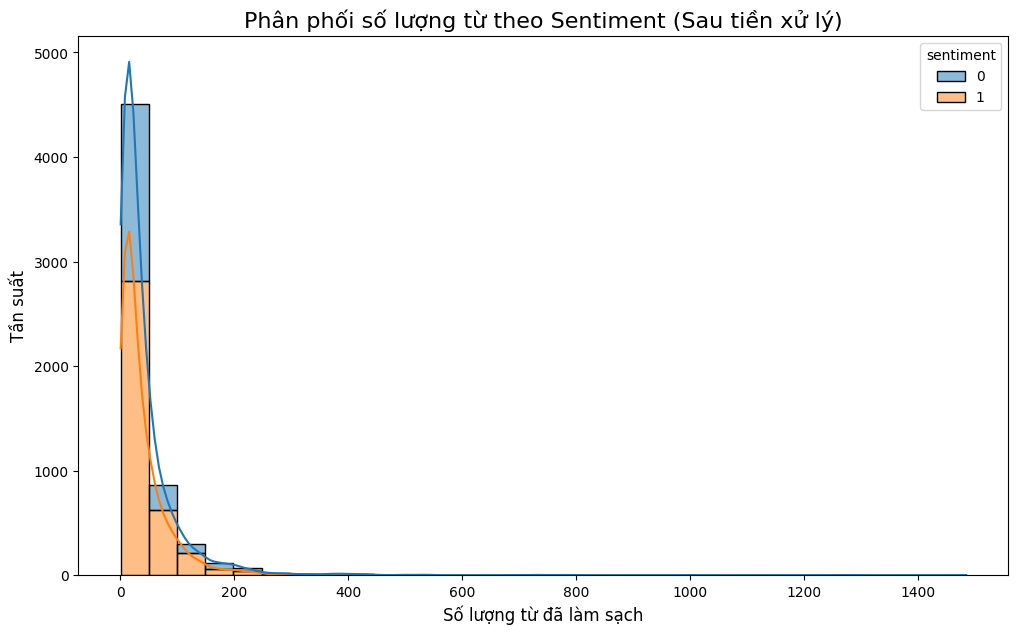


--- Bước 3: Phân tích N-Gram trên dữ liệu sạch ---


/tmp/ipython-input-3751445558.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_depression, y=top_bigrams_depression, ax=axes[0], palette='Reds_d')
/tmp/ipython-input-3751445558.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_normal, y=top_bigrams_normal, ax=axes[1], palette='Greens_d')


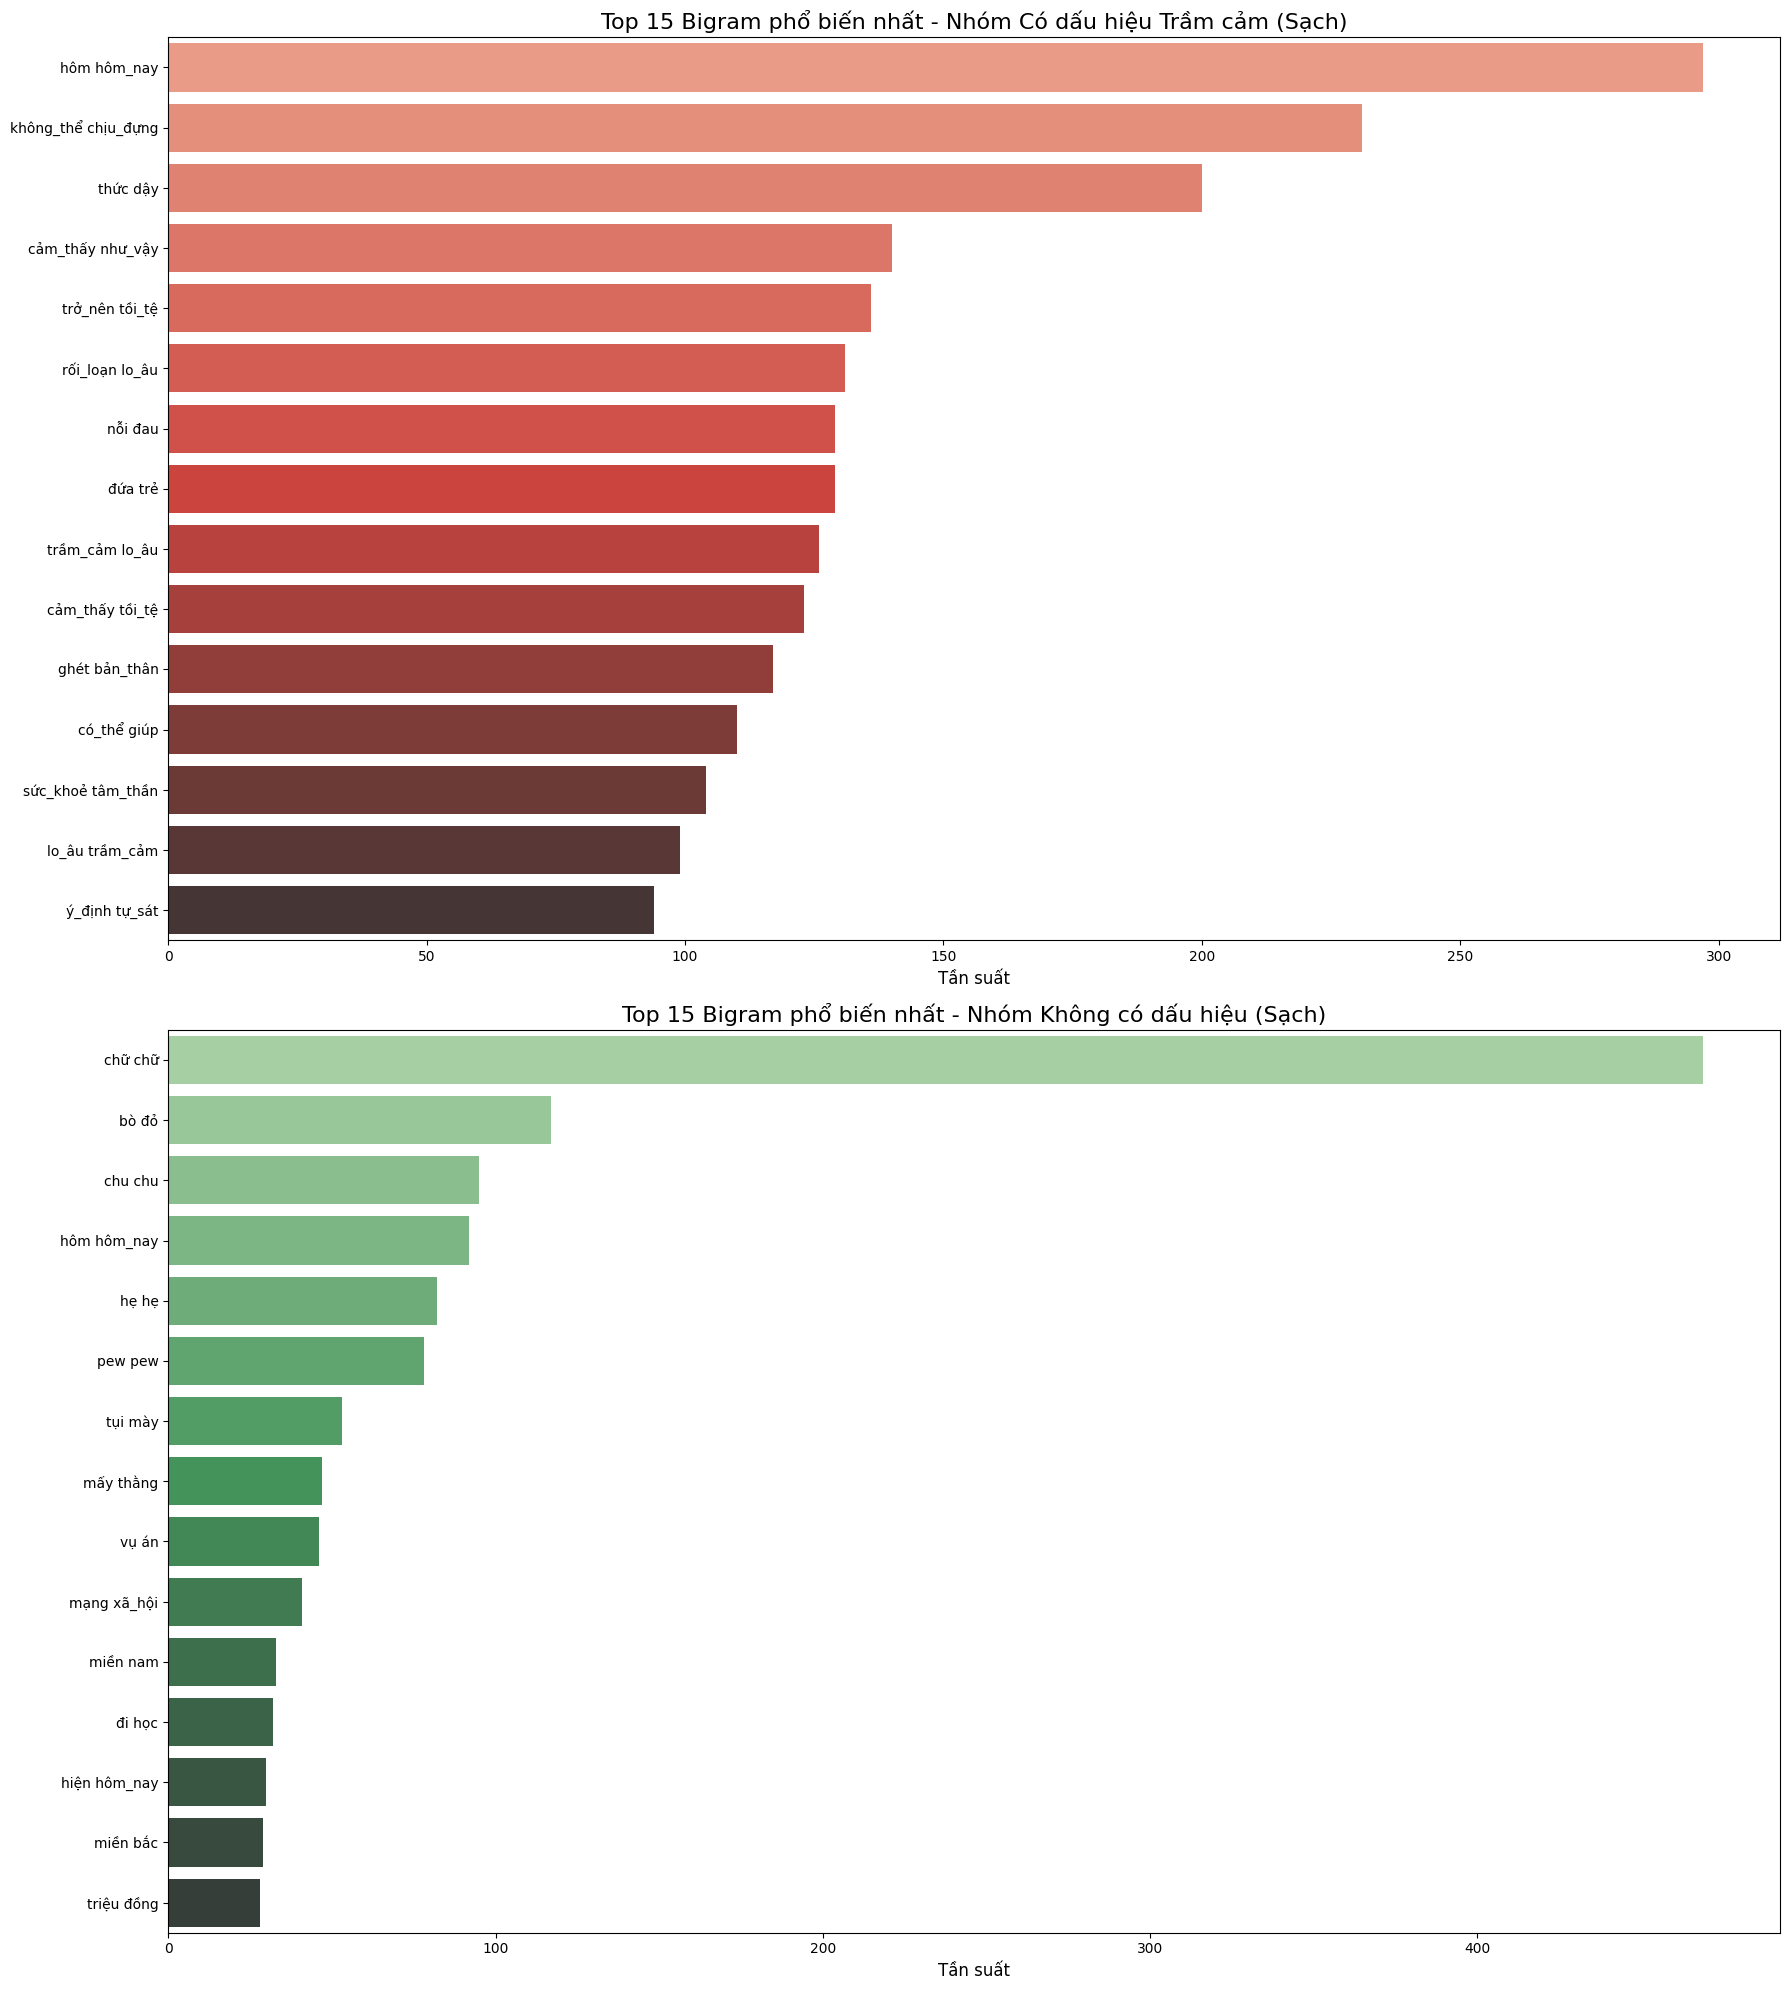


--- Bước 4: Phân tích Word Cloud trên dữ liệu sạch ---


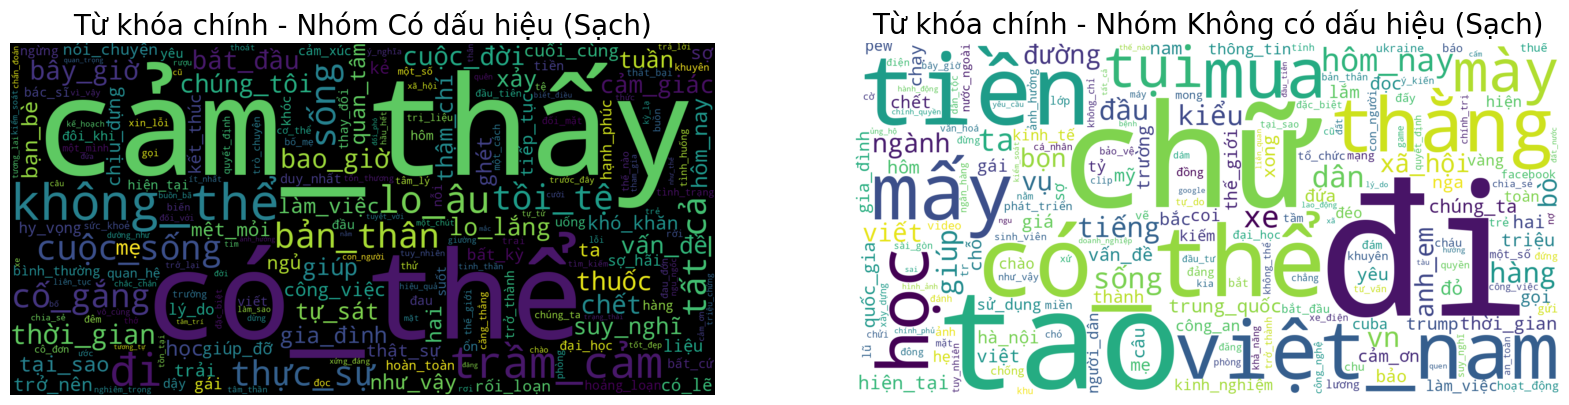


✅ Phân tích trên dữ liệu sạch hoàn tất!


In [ ]:
# ==============================================================================
# --- BƯỚC 3. Phân tích Dữ liệu Khám phá (EDA) trên bộ dữ liệu đã được tiền xử lý Dataset_depression_vi1 ---
# ==============================================================================

# ==============================================================================
# --- 1. TẢI DỮ LIỆU ĐÃ TIỀN XỬ LÝ ---
# ==============================================================================
print("\n--- Bước 1: Tải dữ liệu ---")

BASE_PATH = '/content/drive/MyDrive/tram_cam'
preprocessed_dataset_1_path = os.path.join(BASE_PATH, "Dataset_depression_vi1.csv")

TEXT_COLUMN_NAME = 'text_clean_tfidf'


try:
    df = pd.read_csv(preprocessed_dataset_1_path)

    # Bỏ các dòng có text_clean_tfidf bị rỗng
    df.dropna(subset=[TEXT_COLUMN_NAME], inplace=True)
    df = df[df[TEXT_COLUMN_NAME] != '']

    print(f"✅ Tải và chuẩn bị thành công {len(df)} dòng dữ liệu.")
    print("Thông tin dữ liệu:")
    df.info()
except Exception as e:
    print(f"⚠️ Lỗi khi đọc dữ liệu: {e}")


# ==============================================================================
# --- 2. PHÂN TÍCH THỐNG KÊ (PHÂN PHỐI SỐ LƯỢNG TỪ SẠCH) ---
# ==============================================================================
if 'df' in locals():
    print("\n--- Bước 2: Phân tích Phân phối số lượng từ đã làm sạch ---")

    # Tính toán số lượng từ trên cột TEXT_COLUMN_NAME
    df['word_count_clean'] = df[TEXT_COLUMN_NAME].astype(str).apply(lambda x: len(x.split()))

    print("\nThống kê mô tả về số lượng từ (trên dữ liệu sạch):")
    print(df.groupby('sentiment')['word_count_clean'].describe())

    # Vẽ biểu đồ Histogram
    plt.figure(figsize=(12, 7))
    sns.histplot(data=df, x='word_count_clean', hue='sentiment', multiple='stack', bins=30, kde=True)
    plt.title('Phân phối số lượng từ theo Sentiment (Sau tiền xử lý)', fontsize=16)
    plt.xlabel('Số lượng từ đã làm sạch', fontsize=12)
    plt.ylabel('Tần suất', fontsize=12)
    plt.show()

# ==============================================================================
# --- 3. PHÂN TÍCH N-GRAM TRÊN DỮ LIỆU SẠCH ---
# ==============================================================================
if 'df' in locals():
    print("\n--- Bước 3: Phân tích N-Gram trên dữ liệu sạch ---")

    def get_top_ngrams_from_clean_text(corpus, n=15, gram=2):
        tokens = [tok for text in corpus for tok in str(text).split()]
        ngrams = zip(*[tokens[i:] for i in range(gram)])
        ngram_counts = Counter(ngrams)
        top_ngrams = ngram_counts.most_common(n)
        return [" ".join(gram) for gram, count in top_ngrams], [count for gram, count in top_ngrams]

    text_depression_clean = df[df['sentiment'] == 1][TEXT_COLUMN_NAME]
    text_normal_clean = df[df['sentiment'] == 0][TEXT_COLUMN_NAME]

    top_bigrams_depression, counts_depression = get_top_ngrams_from_clean_text(text_depression_clean, gram=2)
    top_bigrams_normal, counts_normal = get_top_ngrams_from_clean_text(text_normal_clean, gram=2)

    if top_bigrams_depression and top_bigrams_normal:
        fig, axes = plt.subplots(2, 1, figsize=(18, 20))
        sns.barplot(x=counts_depression, y=top_bigrams_depression, ax=axes[0], palette='Reds_d')
        axes[0].set_title('Top 15 Bigram phổ biến nhất - Nhóm Có dấu hiệu Trầm cảm (Sạch)', fontsize=16)
        axes[0].set_xlabel('Tần suất', fontsize=12)

        sns.barplot(x=counts_normal, y=top_bigrams_normal, ax=axes[1], palette='Greens_d')
        axes[1].set_title('Top 15 Bigram phổ biến nhất - Nhóm Không có dấu hiệu (Sạch)', fontsize=16)
        axes[1].set_xlabel('Tần suất', fontsize=12)
        plt.tight_layout()
        plt.show()
    else:
        print("Không có đủ dữ liệu n-gram để vẽ biểu đồ.")

# ==============================================================================
# --- 4. PHÂN TÍCH WORD CLOUD TRÊN DỮ LIỆU SẠCH ---
# ==============================================================================
if 'df' in locals():
    print("\n--- Bước 4: Phân tích Word Cloud trên dữ liệu sạch ---")

    text_for_wc_depression = " ".join(text_depression_clean.astype(str))
    text_for_wc_normal = " ".join(text_normal_clean.astype(str))

    if text_for_wc_depression and text_for_wc_normal:
        wordcloud_depression = WordCloud(width=1600, height=800, background_color='black', collocations=False).generate(text_for_wc_depression)
        wordcloud_normal = WordCloud(width=1600, height=800, background_color='white', collocations=False).generate(text_for_wc_normal)
        fig, ax = plt.subplots(1, 2, figsize=(20, 10))
        ax[0].imshow(wordcloud_depression, interpolation='bilinear')
        ax[0].set_title('Từ khóa chính - Nhóm Có dấu hiệu (Sạch)', fontsize=20)
        ax[0].axis('off')
        ax[1].imshow(wordcloud_normal, interpolation='bilinear')
        ax[1].set_title('Từ khóa chính - Nhóm Không có dấu hiệu (Sạch)', fontsize=20)
        ax[1].axis('off')
        plt.show()
    else:
        print("Không đủ nội dung để tạo Word Cloud.")

    print("\n✅ Phân tích trên dữ liệu sạch hoàn tất!")


--- Bước 1: Tải dữ liệu ---
⚠️ Lỗi khi đọc dữ liệu: [Errno 2] No such file or directory: '/content/drive/MyDrive/tram_cam/Dataset_depression_vi2.csv.csv'

--- Bước 2: Phân tích Phân phối số lượng từ đã làm sạch ---

Thống kê mô tả về số lượng từ (trên dữ liệu sạch):
            count      mean        std  min   25%   50%   75%     max
sentiment                                                            
0          2143.0  43.10686  75.860419  1.0  11.0  22.0  42.0  1485.0
1          3778.0  40.97009  54.858703  1.0  11.0  24.0  51.0  1281.0


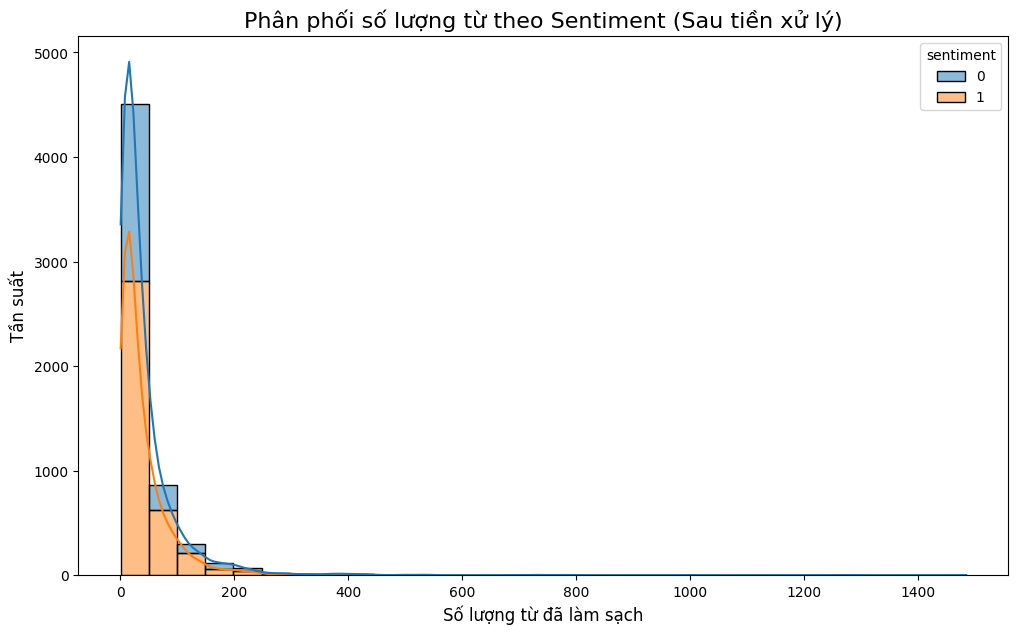


--- Bước 3: Phân tích N-Gram trên dữ liệu sạch ---


/tmp/ipython-input-4195873456.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_depression, y=top_bigrams_depression, ax=axes[0], palette='Reds_d')
/tmp/ipython-input-4195873456.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_normal, y=top_bigrams_normal, ax=axes[1], palette='Greens_d')


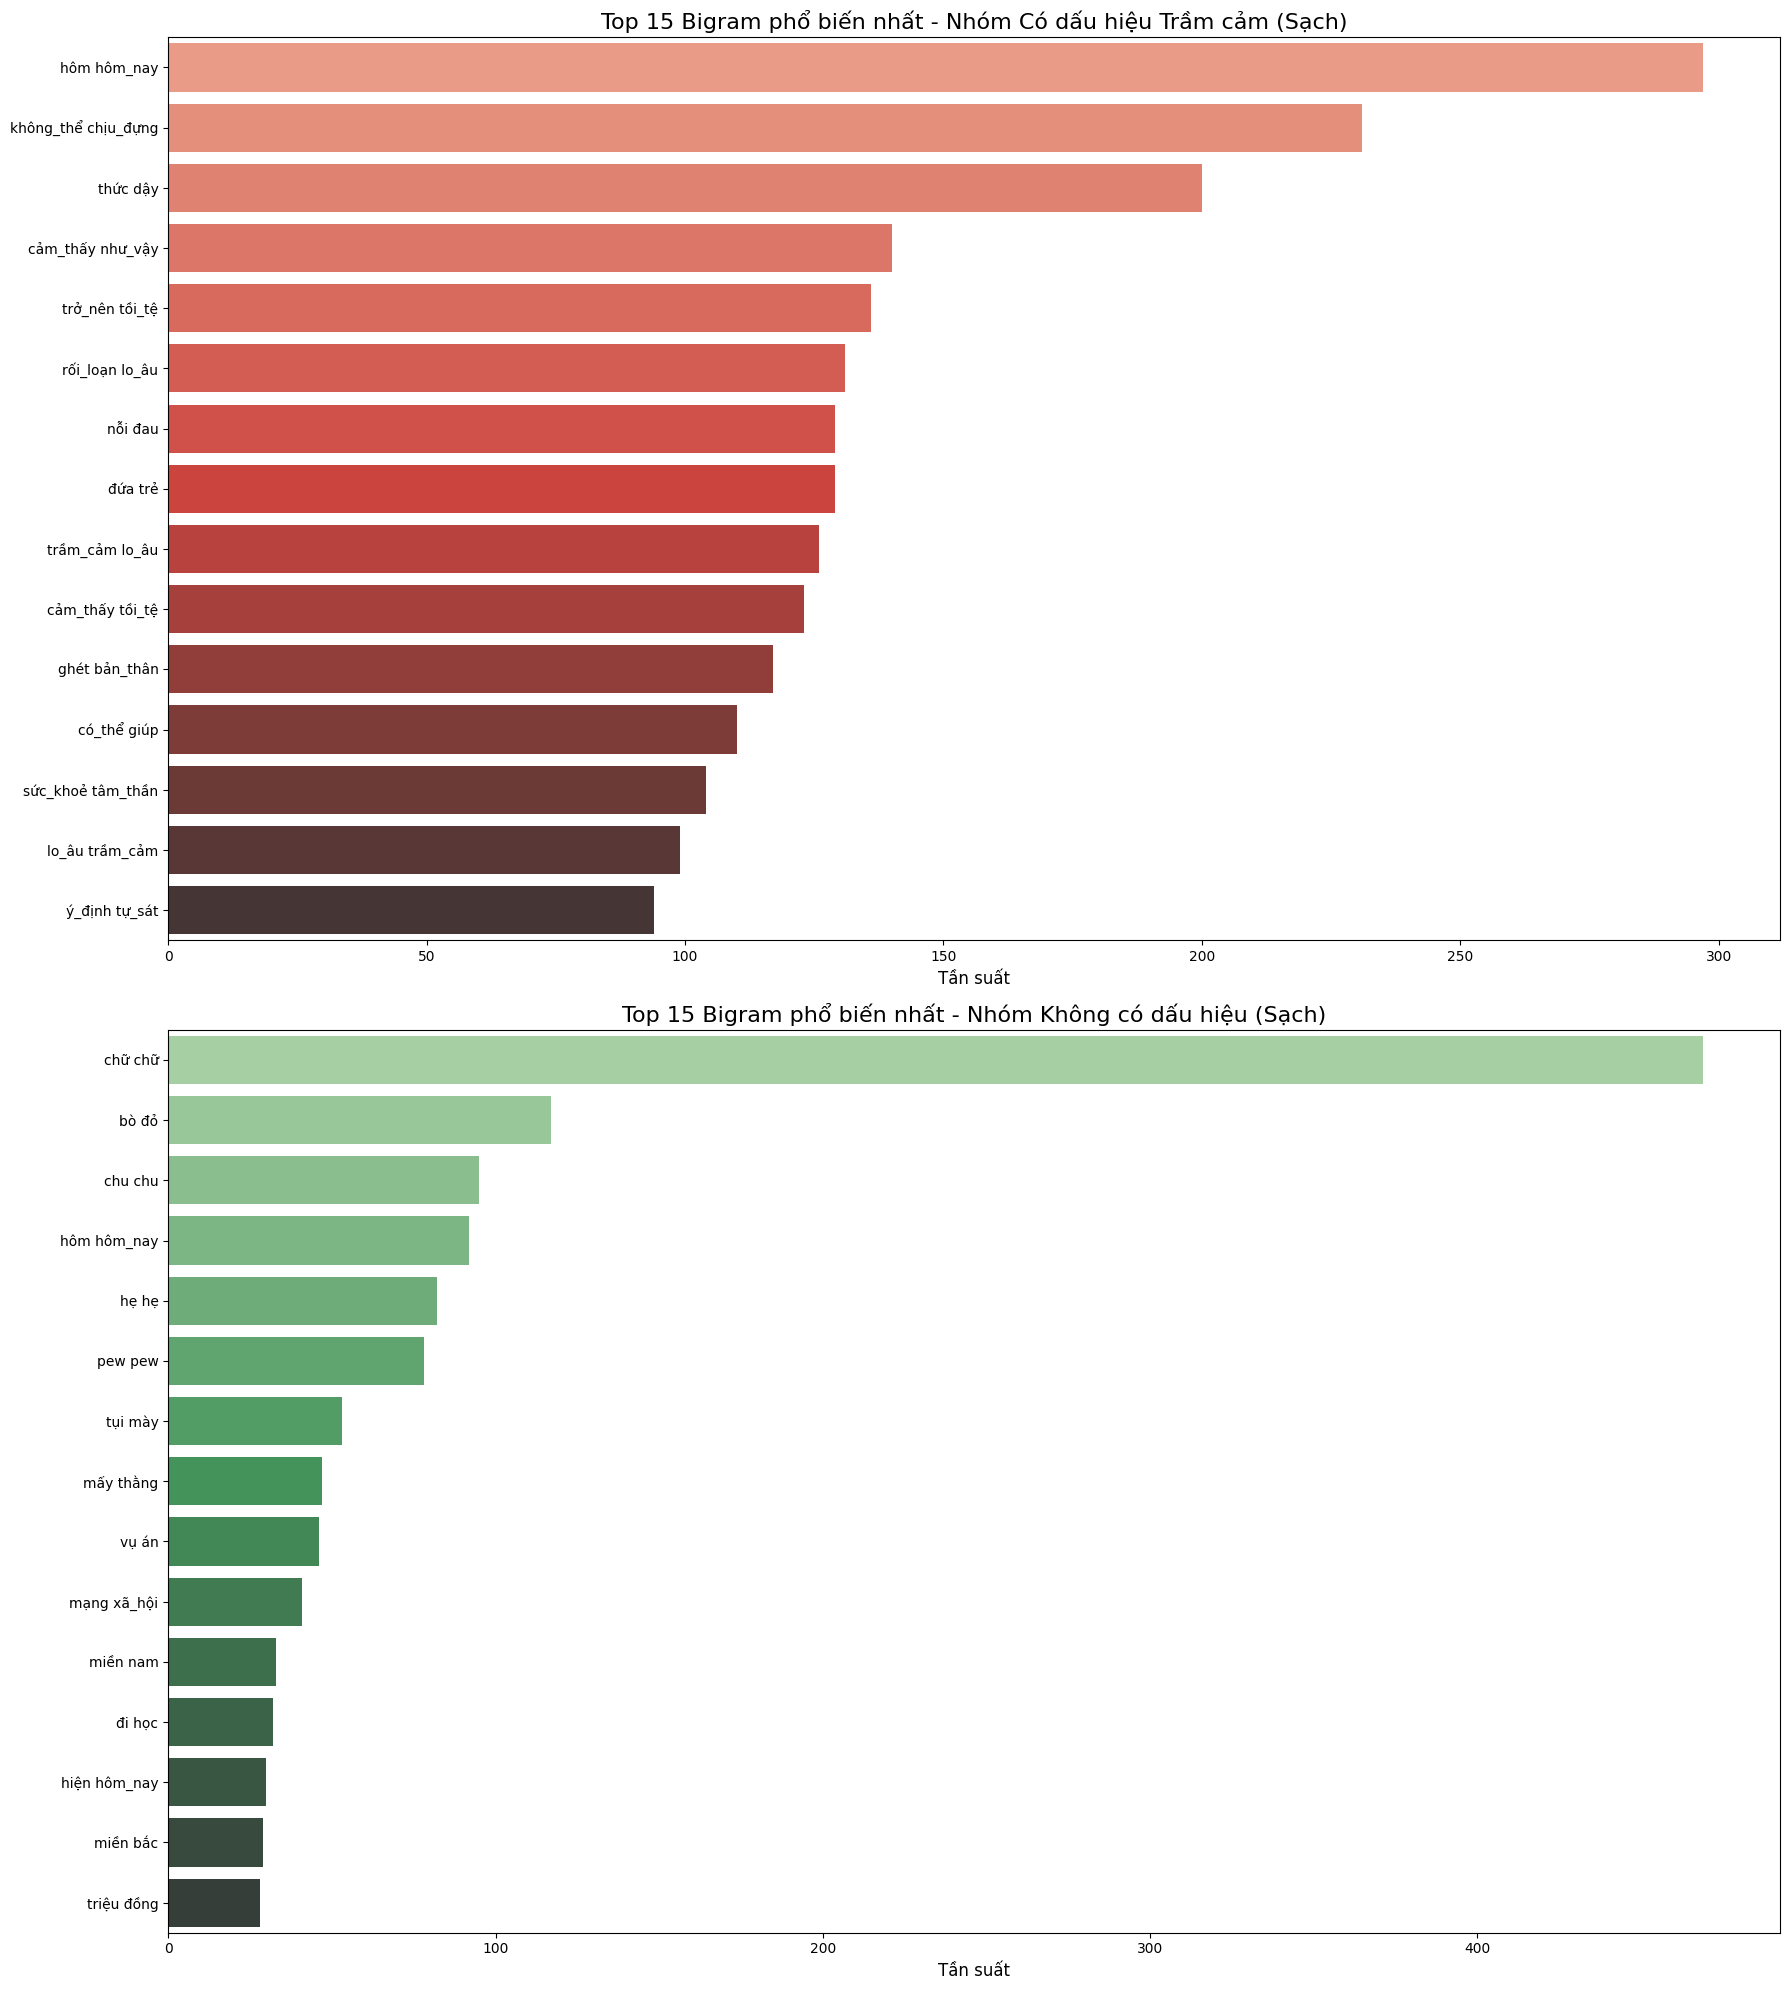


--- Bước 4: Phân tích Word Cloud trên dữ liệu sạch ---


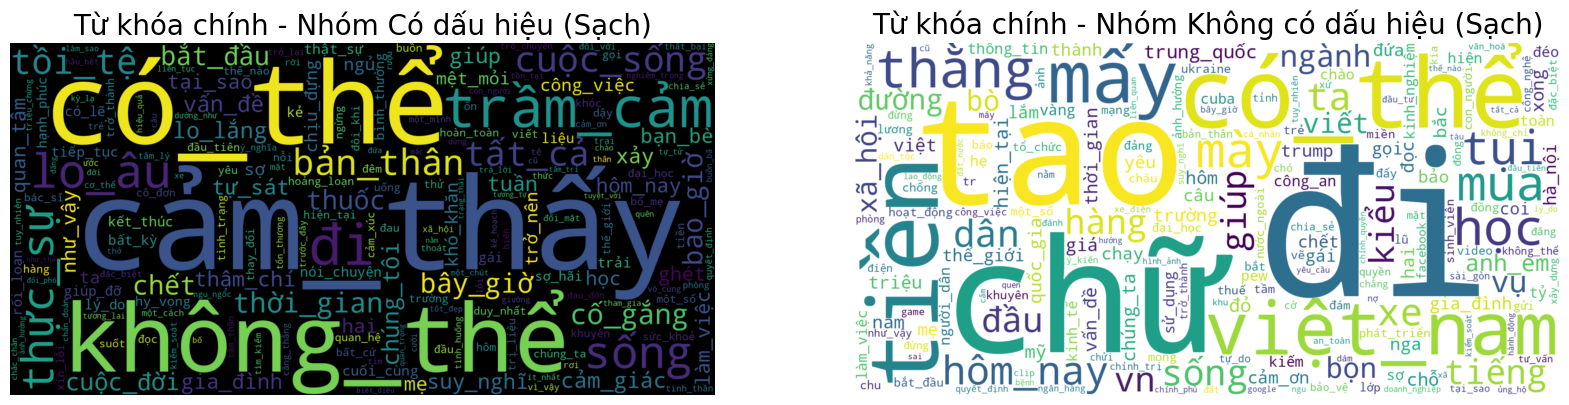


✅ Phân tích trên dữ liệu sạch hoàn tất!


In [ ]:
# ==============================================================================
# --- BƯỚC 3. Phân tích Dữ liệu Khám phá (EDA) trên bộ dữ liệu đã được tiền xử lý Dataset_depression_vi2 ---
# ==============================================================================

# ==============================================================================
# --- 1. TẢI DỮ LIỆU ĐÃ TIỀN XỬ LÝ ---
# ==============================================================================
print("\n--- Bước 1: Tải dữ liệu ---")

BASE_PATH = '/content/drive/MyDrive/tram_cam'
preprocessed_dataset_2_path = os.path.join(BASE_PATH, "Dataset_depression_vi2.csv.csv")

TEXT_COLUMN_NAME = 'text_clean_tfidf'


try:
    df = pd.read_csv(preprocessed_dataset_2_path)

    # Bỏ các dòng có text_clean_tfidf bị rỗng
    df.dropna(subset=[TEXT_COLUMN_NAME], inplace=True)
    df = df[df[TEXT_COLUMN_NAME] != '']

    print(f"✅ Tải và chuẩn bị thành công {len(df)} dòng dữ liệu.")
    print("Thông tin dữ liệu:")
    df.info()
except Exception as e:
    print(f"⚠️ Lỗi khi đọc dữ liệu: {e}")


# ==============================================================================
# --- 2. PHÂN TÍCH THỐNG KÊ (PHÂN PHỐI SỐ LƯỢNG TỪ SẠCH) ---
# ==============================================================================
if 'df' in locals():
    print("\n--- Bước 2: Phân tích Phân phối số lượng từ đã làm sạch ---")

    # Tính toán số lượng từ trên cột TEXT_COLUMN_NAME
    df['word_count_clean'] = df[TEXT_COLUMN_NAME].astype(str).apply(lambda x: len(x.split()))

    print("\nThống kê mô tả về số lượng từ (trên dữ liệu sạch):")
    print(df.groupby('sentiment')['word_count_clean'].describe())

    # Vẽ biểu đồ Histogram
    plt.figure(figsize=(12, 7))
    sns.histplot(data=df, x='word_count_clean', hue='sentiment', multiple='stack', bins=30, kde=True)
    plt.title('Phân phối số lượng từ theo Sentiment (Sau tiền xử lý)', fontsize=16)
    plt.xlabel('Số lượng từ đã làm sạch', fontsize=12)
    plt.ylabel('Tần suất', fontsize=12)
    plt.show()

# ==============================================================================
# --- 3. PHÂN TÍCH N-GRAM TRÊN DỮ LIỆU SẠCH ---
# ==============================================================================
if 'df' in locals():
    print("\n--- Bước 3: Phân tích N-Gram trên dữ liệu sạch ---")

    def get_top_ngrams_from_clean_text(corpus, n=15, gram=2):
        tokens = [tok for text in corpus for tok in str(text).split()]
        ngrams = zip(*[tokens[i:] for i in range(gram)])
        ngram_counts = Counter(ngrams)
        top_ngrams = ngram_counts.most_common(n)
        return [" ".join(gram) for gram, count in top_ngrams], [count for gram, count in top_ngrams]

    text_depression_clean = df[df['sentiment'] == 1][TEXT_COLUMN_NAME]
    text_normal_clean = df[df['sentiment'] == 0][TEXT_COLUMN_NAME]

    top_bigrams_depression, counts_depression = get_top_ngrams_from_clean_text(text_depression_clean, gram=2)
    top_bigrams_normal, counts_normal = get_top_ngrams_from_clean_text(text_normal_clean, gram=2)

    if top_bigrams_depression and top_bigrams_normal:
        fig, axes = plt.subplots(2, 1, figsize=(18, 20))
        sns.barplot(x=counts_depression, y=top_bigrams_depression, ax=axes[0], palette='Reds_d')
        axes[0].set_title('Top 15 Bigram phổ biến nhất - Nhóm Có dấu hiệu Trầm cảm (Sạch)', fontsize=16)
        axes[0].set_xlabel('Tần suất', fontsize=12)

        sns.barplot(x=counts_normal, y=top_bigrams_normal, ax=axes[1], palette='Greens_d')
        axes[1].set_title('Top 15 Bigram phổ biến nhất - Nhóm Không có dấu hiệu (Sạch)', fontsize=16)
        axes[1].set_xlabel('Tần suất', fontsize=12)
        plt.tight_layout()
        plt.show()
    else:
        print("Không có đủ dữ liệu n-gram để vẽ biểu đồ.")

# ==============================================================================
# --- 4. PHÂN TÍCH WORD CLOUD TRÊN DỮ LIỆU SẠCH ---
# ==============================================================================
if 'df' in locals():
    print("\n--- Bước 4: Phân tích Word Cloud trên dữ liệu sạch ---")

    text_for_wc_depression = " ".join(text_depression_clean.astype(str))
    text_for_wc_normal = " ".join(text_normal_clean.astype(str))

    if text_for_wc_depression and text_for_wc_normal:
        wordcloud_depression = WordCloud(width=1600, height=800, background_color='black', collocations=False).generate(text_for_wc_depression)
        wordcloud_normal = WordCloud(width=1600, height=800, background_color='white', collocations=False).generate(text_for_wc_normal)
        fig, ax = plt.subplots(1, 2, figsize=(20, 10))
        ax[0].imshow(wordcloud_depression, interpolation='bilinear')
        ax[0].set_title('Từ khóa chính - Nhóm Có dấu hiệu (Sạch)', fontsize=20)
        ax[0].axis('off')
        ax[1].imshow(wordcloud_normal, interpolation='bilinear')
        ax[1].set_title('Từ khóa chính - Nhóm Không có dấu hiệu (Sạch)', fontsize=20)
        ax[1].axis('off')
        plt.show()
    else:
        print("Không đủ nội dung để tạo Word Cloud.")

    print("\n✅ Phân tích trên dữ liệu sạch hoàn tất!")